# 03 · Topics y contrato de datos

[Índice MQTT](00_indice_mqtt.ipynb) · [Anterior](02_broker_mosquitto_y_red.ipynb) · [Siguiente](04_ingesta_reintentos_y_diagnostico.ipynb)

## Inventario de temas del monitor

La placa define un prefijo `dispositivo/ESP32_S3_0001` a partir de `DEVICE_ID` y le añade el sufijo correspondiente. Python acepta identificadores imprimibles de hasta 128 caracteres sin `/`, `+` ni `#`. Para reutilizar la misma estructura con varias placas, asigna un `DEVICE_ID` único a cada una.

| Tema concreto | Productor | Payload y alcance |
| --- | --- | --- |
| `dispositivo/ESP32_S3_0001/tratado` | ESP32 en directo, o Python tras conversión | JSON. El firmware publica en QoS 0 y Python en QoS 1. |
| `dispositivo/ESP32_S3_0001/crudo` | ESP32 al recuperar pendientes | CSV UTF-8 con cabecera y una sola fila. QoS 0. |
| `dispositivo/ESP32_S3_0001/ack` | Python tras confirmación | ID exacto de la fila en texto plano. QoS 1. |
| `dispositivo/ESP32_S3_0001/estado` | ESP32 al conectar o broker por Last Will | Texto `conectado` en QoS 0 o `desconectado` en QoS 1. Ambos retenidos. |

El backend se suscribe a `dispositivo/+/tratado` y `dispositivo/+/estado`, y añade `dispositivo/+/crudo` en el modo integrado predeterminado. La placa es el consumidor de `ack`. El puente independiente se suscribe únicamente a `dispositivo/+/crudo`.

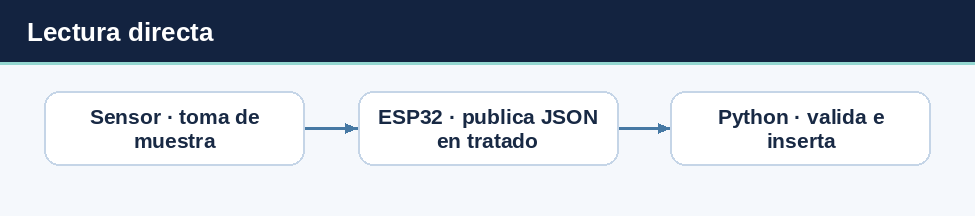

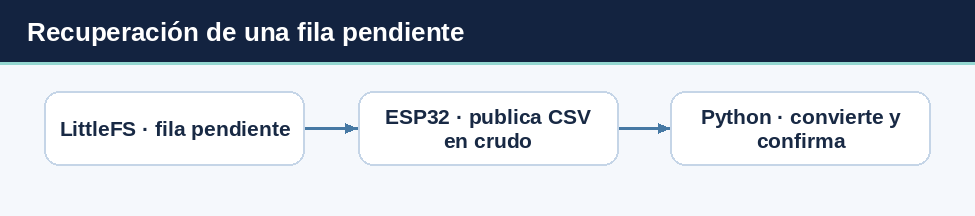

## JSON de una lectura directa

`buildMeasurementJson()` usa ArduinoJson para serializar la muestra del firmware. La estructura tiene un objeto raíz con el ID, la hora y tres series de mediciones. Cada valor conserva metadatos para consumidores del protocolo. El ejemplo muestra una lectura sintética compatible con ese contrato.

```json
{
  "device_id": "ESP32_S3_0001",
  "timestamp": "2026-11-20T14:30:00-06:00",
  "measurements": {
    "temperature": {"sensor": "DHT11", "value": 25.0, "unit": "°C"},
    "humidity": {"sensor": "DHT11", "value": 67.5, "unit": "%RH"},
    "gas": {"sensor": "MQ135", "value": 89.2, "unit": "ppm", "calibrate": false}
  }
}
```

| Campo | Qué significa |
| --- | --- |
| `device_id` | Debe coincidir con el ID del tema. |
| `timestamp` | Hora de medición ISO 8601 con desplazamiento, o `null` mientras la placa carece de hora válida. |
| `temperature.value` | Temperatura DHT11 en grados Celsius, número finito o `null`. |
| `humidity.value` | Humedad relativa DHT11 en porcentaje, número finito o `null`. |
| `gas.value` | Estimación obtenida del MQ135 en ppm, número finito o `null`. El firmware la publica como no calibrada. |
| `gas.calibrate` | Booleano del indicador de calibración. |
| `record_id` | Campo adicional que el backend integrado añade al publicar un CSV convertido. El ESP32 no lo envía en el JSON directo. |

La conversión independiente reconstruye los nombres de sensores y unidades con las constantes del proyecto. En la entrada JSON, el backend valida el tema y el ID, la zona horaria, los tres valores numéricos y el indicador booleano; los valores `sensor` y `unit` forman parte de la convención que genera el publicador. Un valor ausente se representa con `null` y mantiene distinguible el cero real.

## CSV de pendientes y su identidad

CSV representa las columnas y sus valores como texto. El conversor interpreta ese texto según el contrato. Cada fila incluye el ID del registro, el ID de la placa, timestamp, tres números y `calibrate`. Un campo en blanco representa una medición ausente. Para enviar un pendiente se repite la cabecera delante de la fila seleccionada, incluso si el archivo local tiene varias filas.

```csv
id,device_id,timestamp,temperature,humidity,gas,calibrate
0000000100000003,ESP32_S3_0001,2026-11-20T14:30:04-06:00,25.10,67.00,,false
```

1. El conversor verifica tema, UTF-8, cabecera exacta, una sola fila y cantidad de columnas.
2. Compara `device_id` con el tema, requiere un `id` no vacío y admite únicamente `true` o `false` en el último campo.
3. Transforma números finitos en números JSON y campos vacíos en `null`. La función devuelve por separado el ID del registro y el JSON.
4. En modo integrado, `MqttIngest` incorpora el ID como `record_id`, valida el documento y lo guarda antes de publicarlo en `tratado`.

La fila de ejemplo genera `gas.value: null`. Si lleva una fecha vacía, genera también `timestamp: null`. El conversor independiente conserva `timestamp` como texto cuando existe, y la validación estricta de hora ocurre al recibir el JSON en el consumidor integrado.

## Qué hora usa cada consulta

El firmware informa la hora de la muestra con UTC−06:00 cuando su reloj es válido. Al recibir el JSON, el backend exige un desplazamiento horario si existe hora de medición y la normaliza a UTC. PostgreSQL asigna `received_at` al insertarse el registro y define `event_at` como la hora de medición si la hay, o la de recepción en caso contrario.

- **Historial y exportación.** Usan el orden de `event_at`, por eso una fila sin hora de medición sigue consultable.
- **Gráficas temporales.** Agrupan por `measured_at` y excluyen filas sin ella.
- **Lectura presentada como última.** Se toma la más reciente por `event_at` entre las que tienen hora de medición o carecen de `record_id`. Esta regla evita que una recuperación sin reloj sustituya la lectura actual solo por haber llegado después.

El firmware reserva 1024 bytes de buffer MQTT, incluidos los campos del paquete, y el callback Python descarta payloads que excedan 4096 bytes. La cabecera CSV más una sola fila mantiene compacto cada reenvío. Un `/crudo` que no respete el formato no genera `ack`; una fila inválida puede detener el avance de la cola, pues la placa espera su confirmación antes de pasar a la siguiente. [Tamaño de paquete de PubSubClient](https://github.com/knolleary/pubsubclient#limitations)

## Ejercicio de lectura

Predice el resultado de convertir la fila de ejemplo cuando `gas` está vacío. Explica por qué convertirlo a `0` alteraría un promedio. Luego cambia mentalmente el tema a `dispositivo/OTRA_PLACA/crudo`: la validación del ID debe rechazar la fila. Por último, distingue el ID del dispositivo, el ID de la fila y el identificador de paquete de MQTT.

**Código de referencia.** `MonitorAire/src/main.cpp`, `backend/scripts/mqtt_bridge/settings.py`, `backend/scripts/mqtt_bridge/converter.py`, `backend/mqtt_ingest.py` y `backend/schema.sql`.

[Índice MQTT](00_indice_mqtt.ipynb) · [Anterior](02_broker_mosquitto_y_red.ipynb) · [Siguiente](04_ingesta_reintentos_y_diagnostico.ipynb)